# Supplementary Fig S7 · Fig 4A and 4B on every other section

Main Fig 4 shows skin; this figure shows the same on the other sections (replaces the old pan-cancer figure, user 1 Nov).

* **A** Seed 0, every other section whose index genes hold every programme gene (all but lymph node 5k, which keeps
  its 400 most variable genes), the two programmes of Fig 4A (Myeloid, Cytotoxic T; the breast exemplar's query, σ
  matched to the section). Per programme: every cell coloured by the closeness to the query of the index tiles around
  it (percentile of exact d_B^S among the index tiles, lightly smoothed over tile centres, s.d. 1 tile side), and by
  the programme's expression score (mean over the programme genes of the z-scored log-normalised expression), as Fig 4A
  (main tissue only, both as percentiles over the cells drawn).
* **B** Seed 0, every other section, every held-out tile as a gene-set query (|S| = 4 and 16, as Fig 4B): composition
  difference of the query tile to Spindle's first 10 tiles and to a random 10 (mean of 200 draws); bars = medians;
  one-sided Wilcoxon signed-rank test per section and size, Spindle < random (upper bound shown).

**Run first:** `R8_pan_cancer` (`results/pan_cancer/exemplar.csv`) → `R9_skin_maps`
(`results/skin_maps/per_dataset/<key>/seed0_{maps.npz,gene_set_queries.csv}`). Writes `figures/figS7_sections/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.lines import Line2D
from scipy.ndimage import binary_fill_holes, label
from scipy.spatial import cKDTree
from scipy.stats import rankdata, spearmanr, wilcoxon

import style as ps

FIG = "figS7_sections"
RES = ROOT / "results" / "skin_maps" / "per_dataset"
SKIN = "skin_melanoma"  # main Fig 4
KEYS = [k for k in ps.DATASET_ORDER if k != SKIN]
MAP_KEYS = [k for k in KEYS if (RES / k / "seed0_maps.npz").exists()]
SHOWN = ["Myeloid", "Cytotoxic_T"]  # as Fig 4A
PROG_LABELS = {"Cytotoxic_T": "Cytotoxic T", "Myeloid": "Myeloid"}
PROG_COLORS = {"Cytotoxic_T": "#CC3311", "Myeloid": "#009988"}  # as Fig 4A
SMOOTH = 1.0  # Gaussian s.d. of the closeness map, in median tile sides (as Fig 4A)
STEPS = 10
CMAP = ListedColormap(colormaps["viridis"](np.linspace(0, 1, STEPS)))
SIZES = [4, 16]  # as Fig 4B
print("maps:", MAP_KEYS)


def at(fig, x, y, w, h, **kw):
    """Axes w x h mm at (x, y) mm from the panel's top-left corner."""
    W, H_ = ps.size_mm(fig)
    return fig.add_axes([x / W, 1 - (y + h) / H_, w / W, h / H_], **kw)


def text(fig, x, y, s, size=ps.LABEL_PT, ha="left", **kw):
    W, H_ = ps.size_mm(fig)
    fig.text(x / W, 1 - y / H_, s, fontsize=size, ha=ha, va="top", **kw)

maps: ['kidney_nondiseased', 'breast_cancer', 'lung_cancer', 'pancreatic_cancer', 'lymph_node', 'brain_cancer']


## A · Closeness to the query and the programme's expression, cell by cell, on every other section

kidney_nondiseased: 96,782 of 97,560 cells drawn
breast_cancer: 131,761 of 159,226 cells drawn
lung_cancer: 154,492 of 162,254 cells drawn
pancreatic_cancer: 190,340 of 190,965 cells drawn
lymph_node: 356,802 of 377,985 cells drawn
brain_cancer: 814,793 of 816,769 cells drawn
                    Cytotoxic_T  Myeloid
brain_cancer              -0.18     0.35
breast_cancer              0.41     0.53
kidney_nondiseased        -0.08     0.37
lung_cancer                0.29     0.56
lymph_node                 0.75     0.52
pancreatic_cancer         -0.15     0.28
figures/figS7_sections/panels/A.pdf/.png: 180 x 169 mm, 3.7 / 6.6 MB


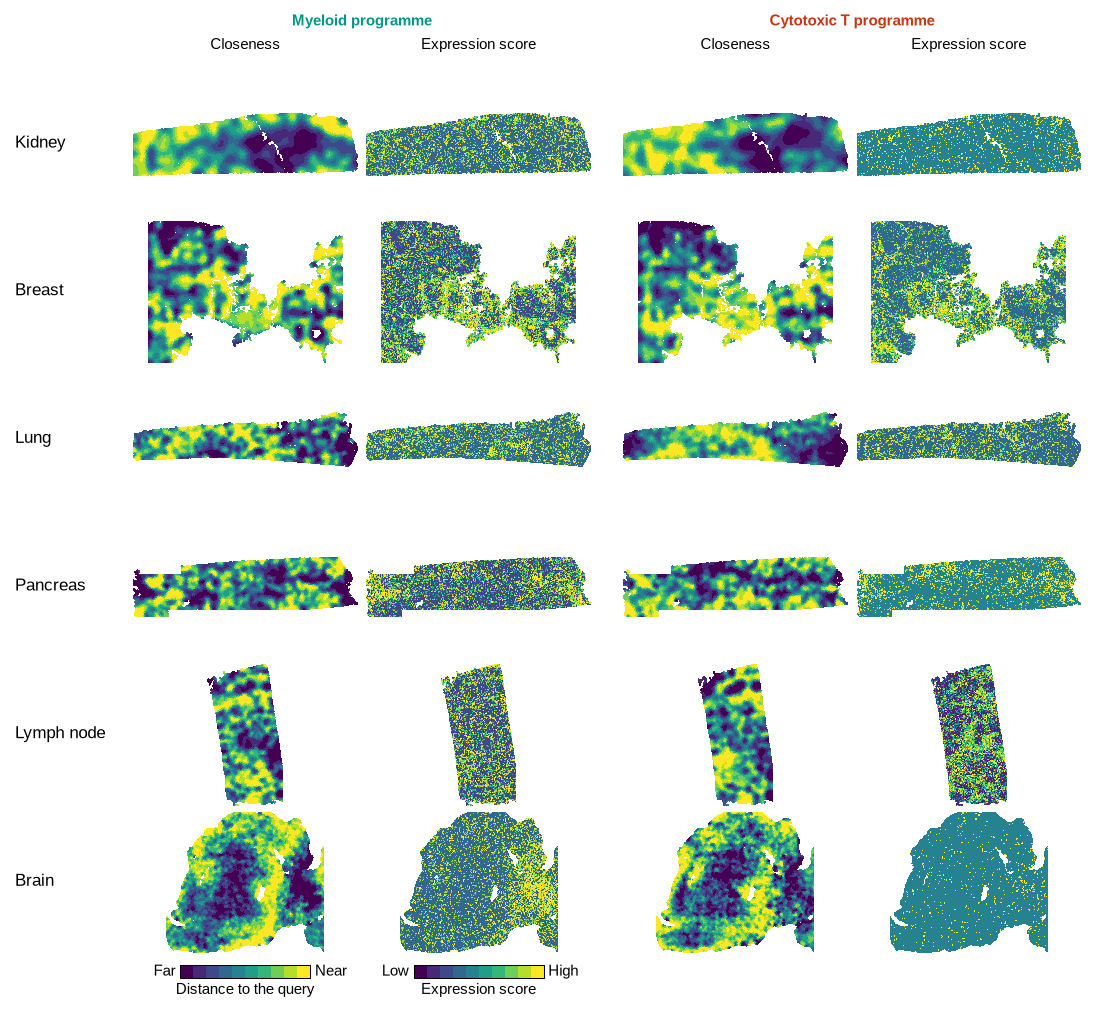

In [2]:
def main_tissue(xy, r=40.0, k=8, px=25.0):
    """Cells drawn (as Fig 4A): those with at least k other cells within r microns, then only the largest connected
    region of their px-micron occupancy grid."""
    dense = np.array([len(v) for v in cKDTree(xy).query_ball_point(xy, r)]) - 1 >= k
    ij = ((xy - xy.min(0)) // px).astype(int)
    occ = np.zeros(ij.max(0) + 1, bool)
    occ[ij[dense, 0], ij[dense, 1]] = True
    lab, _ = label(binary_fill_holes(occ))
    sizes = np.bincount(lab.ravel())
    sizes[0] = 0
    return dense & (lab[ij[:, 0], ij[:, 1]] == np.argmax(sizes))


def percentile(v):
    return (rankdata(v) - 1) / (len(v) - 1)


def closeness_cells(z, xy, prog):
    """As Fig 4A: each index tile's closeness percentile (1 = nearest), Gaussian-averaged at the cell over tile centres
    (s.d. SMOOTH median tile sides, tile area as weight), then the percentile over the cells."""
    v = 1 - percentile(z[f"d_{prog}"])
    ctr, w = z["centre"], z["side"] ** 2
    s2 = 2 * (SMOOTH * np.median(z["side"])) ** 2
    near = cKDTree(ctr)
    out = np.empty(len(xy))
    for i in range(0, len(xy), 4096):
        blk = xy[i:i + 4096]
        # tile centres beyond 5 s.d. weigh < 4e-6 of the nearest: left out for speed
        cand = np.unique(np.concatenate([np.asarray(r, dtype=int) for r in near.query_ball_point(blk, 5 * np.sqrt(s2 / 2))]))
        k = w[cand] * np.exp(-((blk[:, None, :] - ctr[None, cand]) ** 2).sum(-1) / s2)
        out[i:i + 4096] = (k @ v[cand]) / np.maximum(k.sum(1), 1e-300)
    return percentile(out)



MAPS = {}  # key -> (xy drawn, {(prog, kind): percentiles})
for key in MAP_KEYS:
    z = np.load(RES / key / "seed0_maps.npz", allow_pickle=True)
    keep = main_tissue(z["xy"])
    xy = z["xy"][keep]
    vals = {}
    for p in SHOWN:
        vals[p, "close"] = closeness_cells(z, xy, p)
        vals[p, "expr"] = percentile(z[f"score_{p}"][keep].astype(np.float64))
    MAPS[key] = (xy, vals)
    print(f"{key}: {keep.sum():,} of {len(keep):,} cells drawn", flush=True)

# Summary (shown, not saved; quoted in the Supplementary results): Spearman's rho of closeness (-d_B^S) and the
# programme tile score over the index tiles, as R9's match (breast: the exemplar tile left out)
EX = pd.read_csv(ROOT / "results" / "pan_cancer" / "exemplar.csv").set_index("program")
RHO = {}
for key in MAP_KEYS:
    z = np.load(RES / key / "seed0_maps.npz", allow_pickle=True)
    for p in SHOWN:
        v = np.ones(len(z["tiles"]), bool)
        if key == "breast_cancer":
            v[z["tiles"] == int(EX.loc[p, "tile"])] = False
        RHO[key, p] = spearmanr(-z[f"d_{p}"][v], z[f"tile_score_{p}"][v]).statistic
print(pd.Series(RHO).unstack().round(2))

LAB_W, MAP_W, GAP, PAIR_GAP = 20.0, 38.0, 1.5, 4.0
ROW_H, HEAD = 25.0, 10.0
COL_X = [LAB_W + j * (MAP_W + GAP) + (PAIR_GAP if j >= 2 else 0.0) for j in range(4)]
A_W, A_H = 180.0, HEAD + ROW_H * len(MAP_KEYS) + 9.0


def cell_map(ax, xy, v):
    o = np.random.default_rng(0).permutation(len(v))  # random drawing order: no value hides another
    ax.scatter(xy[o, 0], xy[o, 1], s=0.03, c=v[o], cmap=CMAP, vmin=0, vmax=1, lw=0, rasterized=True,
               antialiased=False)
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)
    ax.set_aspect("equal", anchor="C")
    ax.axis("off")


def panel_a(fig):
    for j, p in enumerate(SHOWN):
        x = COL_X[2 * j]
        text(fig, x + MAP_W + GAP / 2, 0.5, f"{PROG_LABELS[p]} programme", ha="center", fontweight="bold",
             color=PROG_COLORS[p], size=ps.TICK_PT)
        text(fig, x + MAP_W / 2, 4.5, "Closeness", ha="center", size=ps.TICK_PT)
        text(fig, x + MAP_W + GAP + MAP_W / 2, 4.5, "Expression score", ha="center", size=ps.TICK_PT)
    for i, key in enumerate(MAP_KEYS):
        y = HEAD + ROW_H * i
        text(fig, 0, y + ROW_H / 2 - 1.5, ps.DATASET_LABELS[key])
        xy, vals = MAPS[key]
        for j, (p, kind) in enumerate([(p, k) for p in SHOWN for k in ("close", "expr")]):
            cell_map(at(fig, COL_X[j], y + 0.5, MAP_W, ROW_H - 1.0), xy, vals[p, kind])
    y = HEAD + ROW_H * len(MAP_KEYS) + 1.5
    for j, (lo, hi, title) in enumerate((("Far", "Near", "Distance to the query"), ("Low", "High", "Expression score"))):
        x = COL_X[j] + 8.0
        bw = MAP_W - 16.0
        cb = fig.colorbar(ScalarMappable(Normalize(0, 1), CMAP), cax=at(fig, x, y, bw, 2.2), orientation="horizontal",
                          ticks=[])
        cb.outline.set_linewidth(0.5)
        text(fig, x - 0.8, y - 0.1, lo, size=ps.TICK_PT, ha="right")
        text(fig, x + bw + 0.8, y - 0.1, hi, size=ps.TICK_PT)
        text(fig, x + bw / 2, y + 3.0, title, size=ps.TICK_PT, ha="center")


fig = ps.panel(A_W, A_H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · Every gene-set query on every other section: composition difference to Spindle's first 10 and a random 10

                            n  none  short
key                size                   
kidney_nondiseased 4       78     0      7
                   8       78     0      0
                   16      78     0      0
                   32      78     0      0
breast_cancer      4      204     0     29
                   8      204     0      9
                   16     204     0      2
                   32     204     0      0
lung_cancer        4      170     0     29
                   8      170     0      3
                   16     170     0      0
                   32     170     0      0
pancreatic_cancer  4      229     0     40
                   8      229     0      2
                   16     229     0      0
                   32     116     0      0
lymph_node         4      261     0     52
                   8      261     0      4
                   16     261     0      1
                   32     258     0      0
lymph_node_5k      4      774     0    149
           

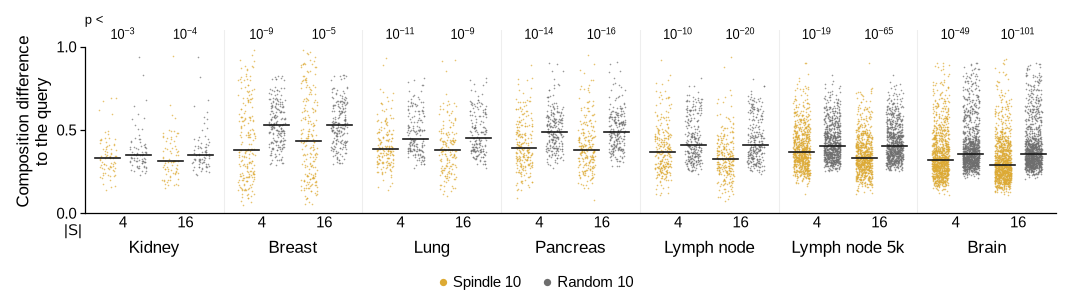

In [3]:
GQ = pd.concat([pd.read_csv(RES / k / "seed0_gene_set_queries.csv") for k in KEYS], ignore_index=True)
print(GQ.groupby(["key", "size"]).agg(n=("query", "size"), none=("n_found", lambda v: int((v == 0).sum())),
                                      short=("n_found", lambda v: int((v < 10).sum()))).loc[KEYS])
GQ = GQ[GQ["size"].isin(SIZES) & (GQ.n_found > 0)]  # no tile returned: left out
P_TV = {}
for (k, L), g in GQ.groupby(["key", "size"]):
    P_TV[k, L] = wilcoxon(g.tv_spindle, g.tv_random, alternative="less").pvalue
summ = GQ.groupby(["key", "size"]).apply(lambda g: pd.Series({
    "n": len(g), "tv_spindle": g.tv_spindle.median(), "tv_random": g.tv_random.median(),
    "below": (g.tv_spindle < g.tv_random).mean()}), include_groups=False)
summ["p"] = [P_TV[i] for i in summ.index]
print(summ.loc[KEYS].round(4))

B_W, B_H = 180.0, 50.0


def p_bound(p):
    return f"10$^{{{int(np.ceil(np.log10(p)))}}}$" if p > 0 else "0"


def panel_b(fig):
    ax = ps.axes(fig, left=14.0, right=1.5, top=6.0, bottom=13.0)
    rng = np.random.default_rng(0)
    w = 1.0 / len(SIZES)
    for i, key in enumerate(KEYS):
        for s, L in enumerate(SIZES):
            g = GQ[(GQ.key == key) & (GQ["size"] == L)]
            xc = i + (s - 0.5) * w * 0.9
            for dx, c, color in ((-0.11, "tv_spindle", ps.TIER_COLORS["spindle_partial"]), (0.11, "tv_random", ps.MUTED)):
                v = g[c].to_numpy()
                ax.scatter(xc + dx + rng.uniform(-0.06, 0.06, len(v)), v, s=0.6, c=color, lw=0, alpha=0.7, zorder=2,
                           rasterized=True)
                ax.plot([xc + dx - 0.09, xc + dx + 0.09], [np.median(v)] * 2, color=ps.INK, lw=0.8, zorder=3)
            ax.text(xc, 1.03, p_bound(P_TV[key, L]), ha="center", va="bottom", fontsize=6.0)
        if i:
            ax.axvline(i - 0.5, color="#EEEEEE", lw=0.5, zorder=0)
    ax.text(-0.5, 1.12, "p <", ha="left", va="bottom", fontsize=6.0)
    ax.set_xticks([i + (s - 0.5) * 0.9 / len(SIZES) for i in range(len(KEYS)) for s in range(len(SIZES))])
    ax.set_xticklabels([str(L) for _ in KEYS for L in SIZES])
    ax.tick_params(axis="x", length=0)
    for i, key in enumerate(KEYS):
        ax.text(i, -0.15, ps.DATASET_LABELS[key], ha="center", va="top", fontsize=ps.LABEL_PT,
                transform=ax.get_xaxis_transform())
    ax.text(-0.52, -0.06, "|S|", ha="right", va="top", fontsize=ps.TICK_PT, transform=ax.get_xaxis_transform())
    ax.set_xlim(-0.5, len(KEYS) - 0.5)
    ax.set_ylim(0, 1.1)
    ax.set_yticks([0, 0.5, 1])
    ax.spines["left"].set_bounds(0, 1)
    ax.set_ylabel("Composition difference\nto the query")
    handles = [Line2D([], [], ls="", marker="o", ms=2.5, color=ps.TIER_COLORS["spindle_partial"], label="Spindle 10"),
               Line2D([], [], ls="", marker="o", ms=2.5, color=ps.MUTED, label="Random 10")]
    fig.legend(handles=handles, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 0.0), handletextpad=0.1,
               columnspacing=1.2)


fig = ps.panel(B_W, B_H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## Full figure

figures/figS7_sections/figS7_sections.pdf/.png: 180 x 221 mm, 4.3 / 8.0 MB


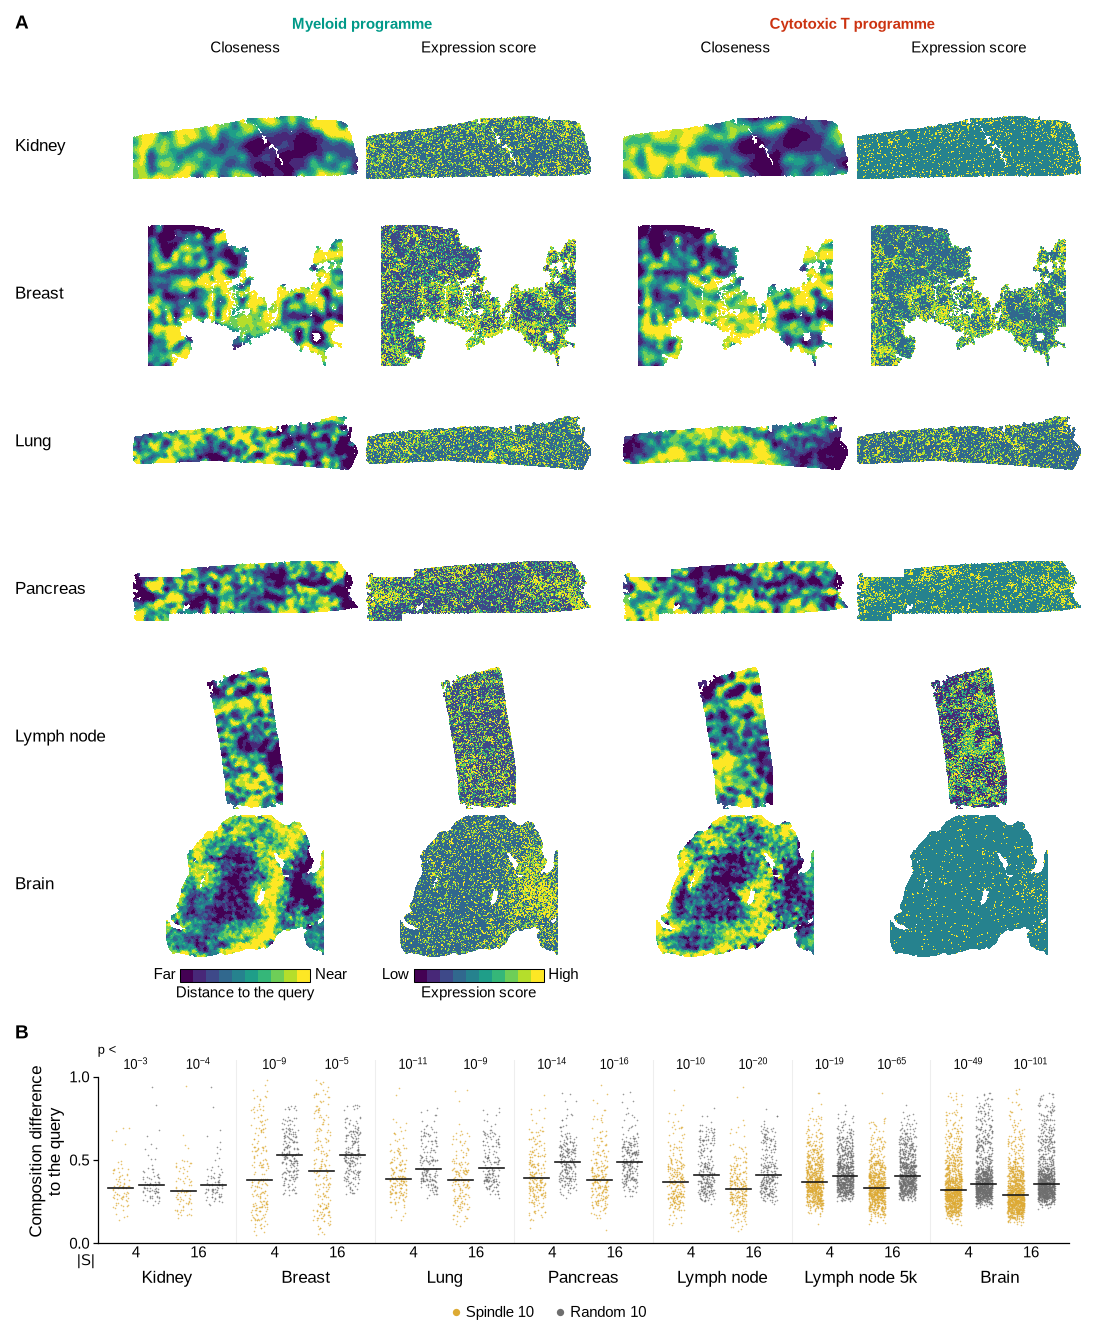

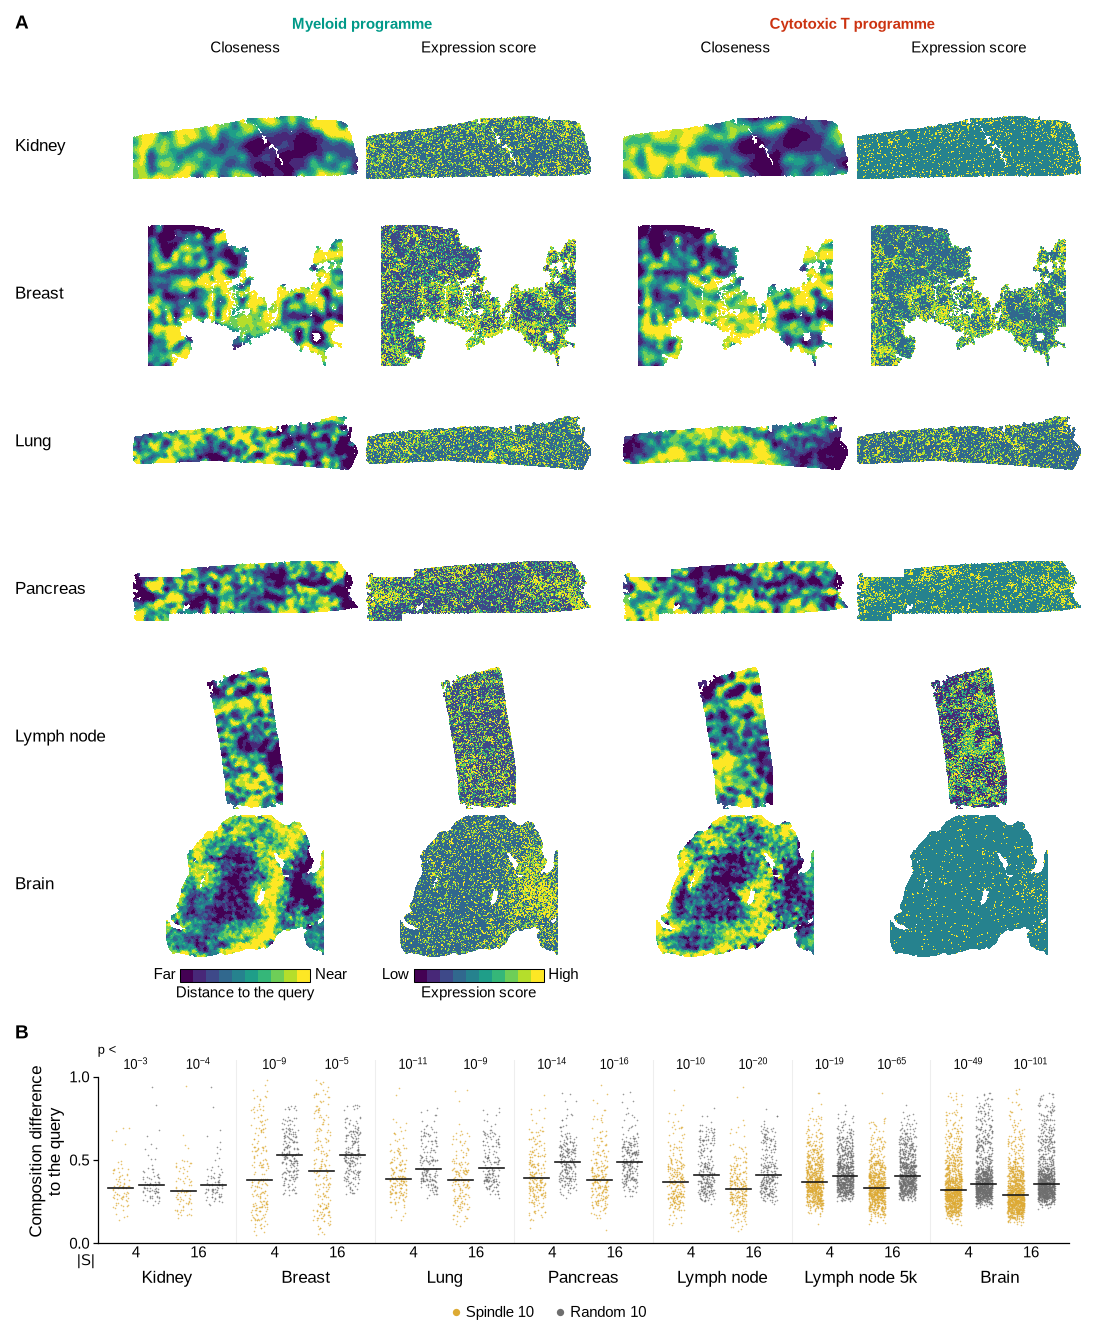

In [4]:
page = ps.page(180, A_H + 2.0 + B_H)
panel_a(ps.place(page, "A", 0, 0, A_W, A_H))
panel_b(ps.place(page, "B", 0, A_H + 2.0, B_W, B_H))
ps.save_figure(page, FIG)
page